#### Natalia Cercos 

# Image Formation in a Telescope

Modern astrophysics is built upon observations, thus it is of great interest to understand how
optical systems work and how they influence the formation of an image in the telescope focus.
Every telescope is characterized by a set of optical elements. Refracting telescopes have lenses,
while reflecting telescopes have a set of mirrors. Each optical element, due to its imperfections,
introduces certain perturbation to the image of the observed object.
The appearance of the object image in the telescope's focus is described with the so-called
Point Spread Function (PSF). The PSF describes the system's response to a point source. In its
base it represents the diffraction pattern of a point source in the telescope's focus. Every optical
system, based on its set of optical elements, will have a unique PSF. Figure 1 shows an example
of the PSF in the system’s focus.

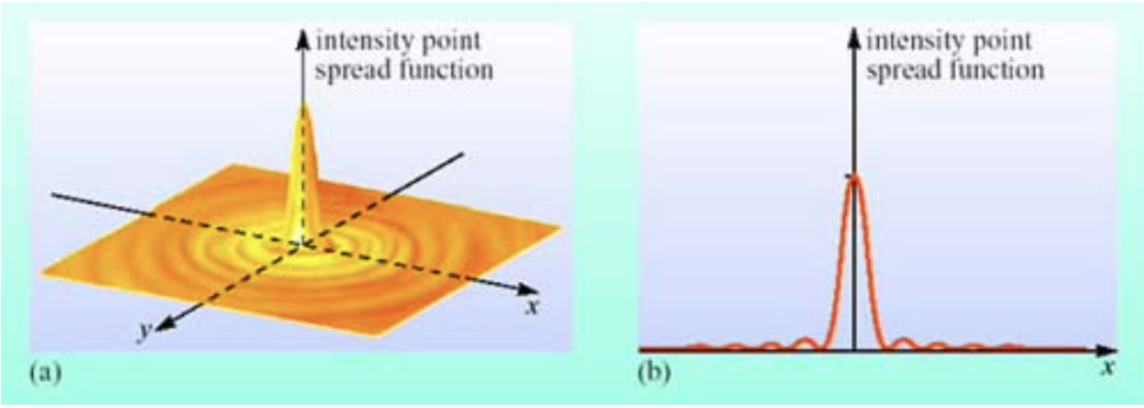

In [2]:
from IPython.display import Image, display
display(Image(filename="Photos1/H2-1.png", width=600))

**Figure 1:** Example PSF of an optical system: (a) 2D distribution of the PSF on the screen (b)
cross-section of this distribution along the x-axis of the screen.


In this exercise, the aim is to explore how the PSF of an optical system is constructed and to
examine its influence on the image formation in the system's focus. Since the telescope aperture
is in most cases circular, we will focus on the ciruclar aperture. However modern, very large
telescopes are segmented. These segments are hexagonal, and because of this, the telescope
aperture is essentially hexagonal.

### Point Spread Function – PSF

The PSF is essentially a diffraction image (distribution of radiation intensity) of the source
projected in the focus of the optical system. In case of astronomical sources, which are are very
distant point sources, the PSF is as a result of the Fraunhofer diffraction on the telescope
apreture. According to Maxwell's electromagnetic theory, light is an electromagnetic wave,
representing oscillations of electric and magnetic fields in space and time. The intensity of light
is defined as the square of the intensity of the electric field. If we know the shape of the electric
field vector at a given point in space, we can easily calculate the radiation intensity at that point,
i.e., we can determine the PSF of the optical system.


Let’s consider a telescope of a circular aperture and calculate the electric field vector at a
specific point behind the aperture. Let’s divide the aperture into small elements (smaller than
the wavelength of the observed light, see Figure 2). From each of these small elements of the
aperture, we can assume that a spherical wave arrives at point P (based on the Huygens-Fresnel
principle). The total electric field vector will be the superposition of the electric field vectors
of each of these waves (i.e. summing over the elements of the telescope's aperture). The
assumption that the aperture segments are smaller than the wavelength guarantees that all
waves will be in the same phase at point P. The value of the electric field at point P will depend
on the position of the wave source (x, y) (the position of the surface element SdS) and the
position of point P. The mathematical operation of superposing these waves at point P is
actually a Fourier transformation of the wavefront at the aperture. This operation converts the
shape of the wavefront at the aperture into its image on the detector located in the focus.

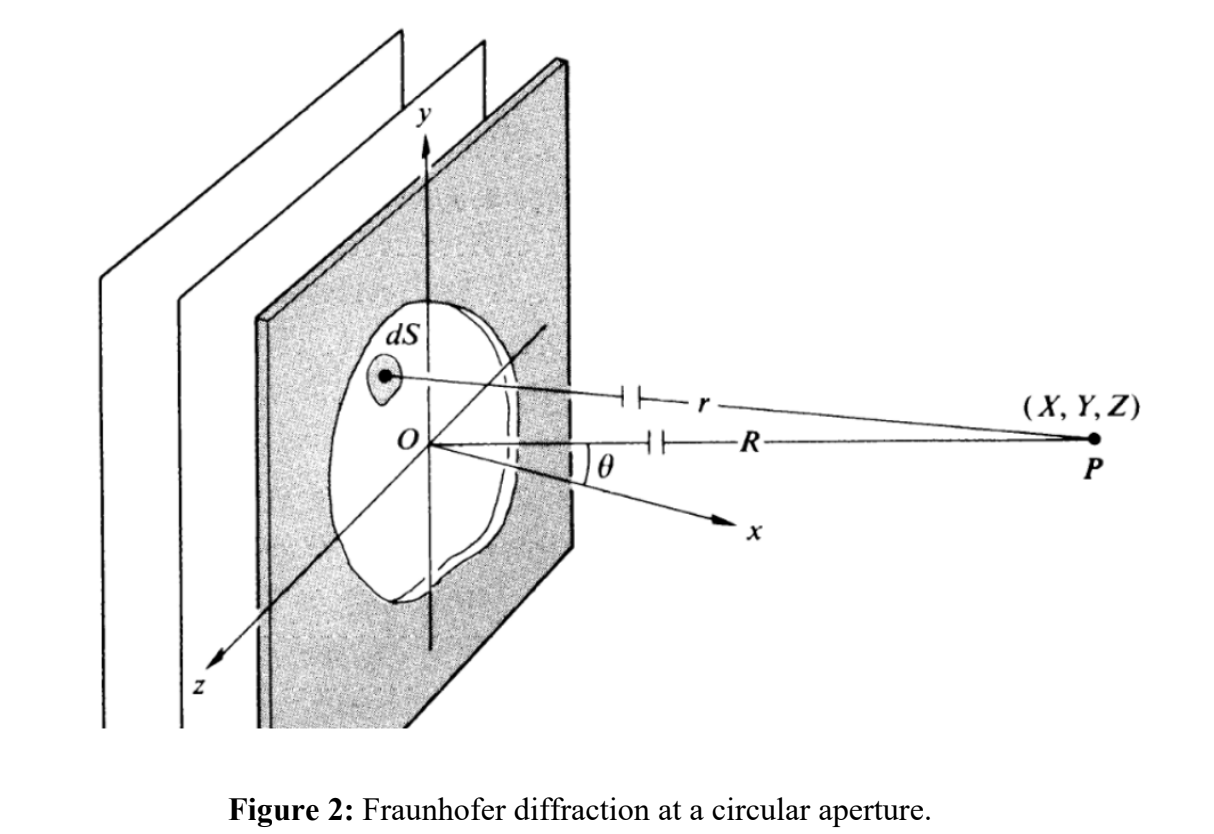

In [3]:
from IPython.display import Image, display
display(Image(filename="Photos1/h2-2.png", width=600))

Since we assumed that a flat wave is arriving at the aperture, the wave will have the same phase
at every point of the aperture, i.e., it will have a constant amplitude and phase. This holds only
if there are no deformations to the wavefront (thiss will be discussed this in more detail later).
From the previous explanation, we can conclude that the wavefront takes the shape of the
telescope aperture (e.g., circular aperture), and from this, we get that the PSF is the square of
the Fourier transform of the telescope aperture A:

$$PSF = |F(A(x,y))|^2$$

Depending on the shape of the aperture, we will have different PSF patterns. In the case of an
ideal system, a flate wave and a circular aperture, the PSF in the focus has the shape of an Airy
function.

### Task 1: 
Calculate the PSF for a circular aperture. Assume that the telescope has a circular
aperture with a radius of 128, 64, and 32, within the field of 256×256 size.



We calculate the PSF for circular apertures with radii of 128, 64, and 32 pixels on a 256 × 256 grid:


$$PSF = |F(A(x,y))|^2$$


The aperture function is 1 inside the circle and 0 outside.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

N = 256
radii = [128, 64, 32] # 0,1,2

y, x = np.indices((N, N))
xc = yc = N // 2

We first construct the aperture with radius 128 pixels, centred on the grid.

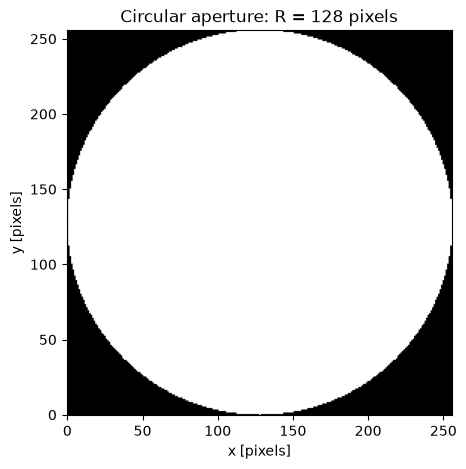

In [7]:
R = radii[0]

aperture = ((x - xc)**2 + (y - yc)**2 <= R**2).astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(aperture, cmap="gray", origin="lower")
plt.title(f"Circular aperture: R = {R} pixels")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

Now to calculate the PSF, we must perform a 2D Fourier transfrom on the aperture. It needs to be normalized. 

In [9]:
# Fourier transform 
amplitude = np.fft.fft2(aperture)

# Centre the diffraction pattern
amplitude = np.fft.fftshift(amplitude)

# Squared modulus gives the intensity
psf = np.abs(amplitude)**2

# Normalise the peak to 1
psf = psf / psf.max()